<a href="https://colab.research.google.com/github/itsmesharafat/Bitcoin-Prediction/blob/main/Bitcoin_ML_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install yfinance
import yfinance as yf
import pandas as pd
import numpy as np
!pip install matplotlib
import matplotlib.pyplot as plt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 23.5 MB/s  0:00:00m0:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 34.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 30.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [matplotlib]6 [matplotlib]


In [3]:
data = yf.download('BTC-USD','2015-01-01','2023-11-30')

[*********************100%***********************]  1 of 1 completed


In [4]:
data = pd.DataFrame(data)

In [5]:
data.reset_index(inplace=True)

In [6]:
# Flatten the MultiIndex columns by keeping only the metric name (e.g., 'Close')
data.columns = data.columns.get_level_values(0)

# Drop the unnecessary columns (note: 'Adj Close' is not in this dataset, so we omit it)
data.drop(columns=['Date', 'Open', 'High', 'Low', 'Volume'], inplace=True)

In [7]:
data

Price,Close
0,314.248993
1,315.032013
2,281.082001
3,264.195007
4,274.473999
...,...
3250,37796.792969
3251,37479.121094
3252,37254.167969
3253,37831.085938


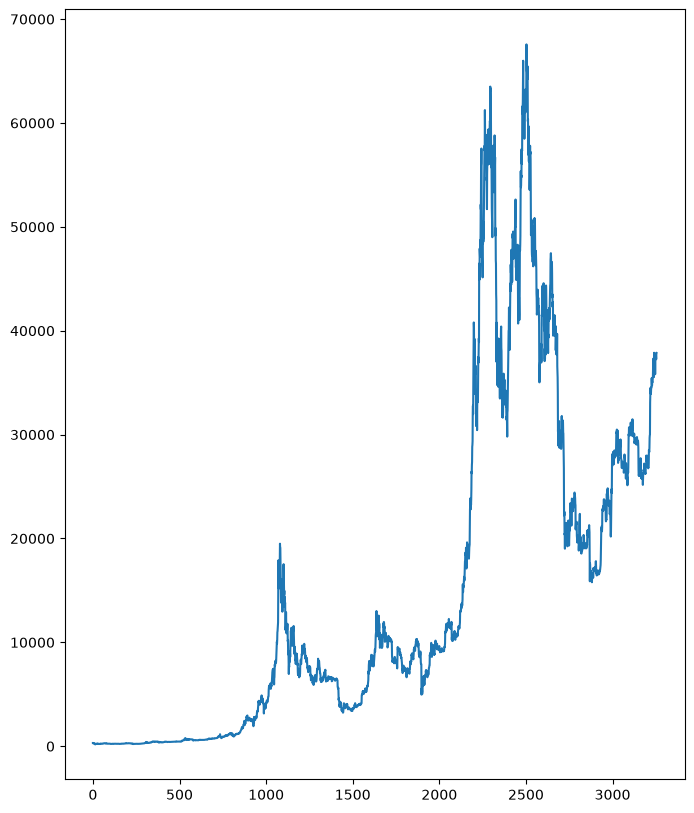

In [8]:
plt.figure(figsize=(8,10))
plt.plot(data)
plt.show()

In [9]:
train_data = data[:-100]
test_data = data[-100:]

In [10]:
train_data.shape

(3155, 1)

In [11]:
test_data.shape

(100, 1)

In [12]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler(feature_range=(0,1))

In [13]:
train_data_scale = scaler.fit_transform(train_data)

In [14]:
base_days = 100

In [15]:
x = []
y = []
for i in range(base_days, train_data_scale.shape[0]):
    x.append(train_data_scale[i-base_days:i])
    y.append(train_data_scale[i,0])

In [16]:
x, y = np.array(x), np.array(y)

In [17]:
x = np.reshape(x, (x.shape[0],x.shape[1],1))

In [18]:
from keras.layers import LSTM, Dense, Dropout
from keras.models import Sequential

I0000 00:00:1791821304.626994    9443 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791821307.356032    9443 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791821312.331852    9443 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [19]:
model = Sequential()
model.add(LSTM(50, activation = 'relu', return_sequences=True, input_shape=(x.shape[1],1)))
model.add(Dropout(0.2))
model.add(LSTM(60, activation='relu',return_sequences=True))
model.add(Dropout(0.3))
model.add(LSTM(80, activation='relu',return_sequences=True))
model.add(Dropout(0.4))
model.add(LSTM(120, activation='relu'))
model.add(Dropout(0.5))

model.add(Dense(units=1))

E0000 00:00:1791821313.022779    9443 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cuda_status.cc:50

/workspaces/Bitcoin-Prediction/.venv/lib/python3.14/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [20]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 100, 50)        │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 100, 50)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 100, 60)        │        26,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 100, 60)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 100, 80)        │        45,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 100, 80)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 120)            │        96,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 120)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           121 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 178,761 (698.29 KB)

 Trainable params: 178,761 (698.29 KB)

 Non-trainable params: 0 (0.00 B)

In [21]:
model.compile(optimizer='adam', loss = 'mean_squared_error')

In [22]:
model.fit(x, y, epochs = 50, verbose =1 )

Epoch 1/50


96/96 ━━━━━━━━━━━━━━━━━━━━ 25s 222ms/step - loss: 0.0173
Epoch 2/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 14s 149ms/step - loss: 0.0055
Epoch 3/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 13s 132ms/step - loss: 0.0044
Epoch 4/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 13s 133ms/step - loss: 0.0042
Epoch 5/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 13s 131ms/step - loss: 0.0043
Epoch 6/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 13s 134ms/step - loss: 0.0040
Epoch 7/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 13s 138ms/step - loss: 0.0039
Epoch 8/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 23s 163ms/step - loss: 0.0033
Epoch 9/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 21s 170ms/step - loss: 0.0035
Epoch 10/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 24s 206ms/step - loss: 0.0030
Epoch 11/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 20s 200ms/step - loss: 0.0030
Epoch 12/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 15s 142ms/step - loss: 0.0030
Epoch 13/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 23s 174ms/step - loss: 0.0027
Epoch 14/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 25s 261ms/step - loss: 0.0028
Epoch 15/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 21s 217ms/step 

In [23]:
test_data = pd.concat((train_data.tail(100), test_data), ignore_index=True)

In [24]:
test_data

Price,Close
0,26930.638672
1,27192.693359
2,27036.650391
3,27398.802734
4,26832.208984
...,...
195,37796.792969
196,37479.121094
197,37254.167969
198,37831.085938


In [25]:
test_data_scale = scaler.transform(test_data)

In [26]:
x = []
y = []

for i in range(base_days, test_data_scale.shape[0]):
    x.append(test_data_scale[i-base_days:i])
    y.append(test_data_scale[i,0])

In [27]:
x, y = np.array(x), np.array(y)

In [28]:
x = np.reshape(x, (x.shape[0],x.shape[1],1))

In [29]:
pred = model.predict(x)

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 142ms/step


In [30]:
pred = scaler.inverse_transform(pred)

In [31]:
pred

array([[26844.55 ],
       [26385.236],
       [26061.258],
       [25876.238],
       [25806.795],
       [25815.41 ],
       [25868.803],
       [25940.15 ],
       [26095.53 ],
       [26340.49 ],
       [26554.025],
       [26650.666],
       [26615.129],
       [26484.035],
       [26301.01 ],
       [26105.064],
       [25925.406],
       [25801.17 ],
       [25736.07 ],
       [25719.014],
       [25730.99 ],
       [25724.572],
       [25704.918],
       [25705.137],
       [25756.072],
       [25869.02 ],
       [26026.71 ],
       [26195.623],
       [26356.11 ],
       [26518.451],
       [26678.482],
       [26791.854],
       [26835.205],
       [26811.49 ],
       [26726.63 ],
       [26601.555],
       [26459.258],
       [26327.87 ],
       [26257.674],
       [26268.428],
       [26353.945],
       [26548.375],
       [26815.848],
       [27088.875],
       [27333.465],
       [27504.299],
       [27615.268],
       [27688.484],
       [27737.498],
       [27747.7  ],


In [32]:
#future Bitcoin Price

In [33]:
# Re-insuring all upstream variables exist in the current session state
base_days = 100
train_data = data[:-100]
test_data = data[-100:]

# Fit the scaler
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler(feature_range=(0,1))
train_data_scale = scaler.fit_transform(train_data)

# Prepare test data with the 100-day window from train_data
test_data_combined = pd.concat((train_data.tail(100), test_data), ignore_index=True)
test_data_scale = scaler.transform(test_data_combined)

# Setup the rolling future prediction
current_batch = test_data_scale[-base_days:].reshape(1, base_days, 1)

future_days = 30
z = []

for i in range(future_days):
    # Predict the next day's scaled price
    pred = model.predict(current_batch, verbose=0)

    # Store prediction
    z.append(pred[0, 0])

    # Update the batch with the newly predicted price
    new_pred_reshaped = pred.reshape(1, 1, 1)
    current_batch = np.append(current_batch[:, 1:, :], new_pred_reshaped, axis=1)

In [34]:
# Convert to numpy array and inverse transform to get actual prices
z = np.array(z).reshape(-1, 1)
z_actual = scaler.inverse_transform(z)

In [35]:
# Display the predicted future prices
display(z_actual)

array([[37303.105],
       [37292.035],
       [37228.613],
       [37124.57 ],
       [36998.086],
       [36864.78 ],
       [36734.586],
       [36612.07 ],
       [36498.34 ],
       [36392.773],
       [36294.254],
       [36201.695],
       [36114.24 ],
       [36031.188],
       [35951.957],
       [35876.03 ],
       [35802.98 ],
       [35732.47 ],
       [35664.113],
       [35597.605],
       [35532.723],
       [35469.28 ],
       [35407.168],
       [35346.29 ],
       [35286.574],
       [35227.992],
       [35170.504],
       [35114.08 ],
       [35058.707],
       [35004.36 ]], dtype=float32)

In [36]:
model.save('Bitcoin_Price_prediction_Model.keras')

In [37]:
# Print columns to inspect the multi-index structure
print("Columns:", data.columns)

# To flatten the multi-index and handle column dropping properly:
# data.columns = data.columns.droplevel(1) # If you want to drop the 'Ticker' level


Columns: Index(['Close'], dtype='str', name='Price')
